# FAHAD BIN SHAFI
# FA23 BAI 033
# Landmark Recognition Using the SIFT Algorithm
**Lab Assignment – Computer Vision (Python + OpenCV)**

This notebook is a complete, runnable solution for Google Colab. Use **Runtime → Run all**.

| Task | Content |
|---|---|
| 1 | Landmark image database (5 landmarks, multiple images each) |
| 2 | SIFT feature extraction on reference images |
| 3 | Query image processing |
| 4 | BF matcher + kNN (k=2) + Lowe's ratio test + thresholded decision |
| 5 | Landmark localization (RANSAC homography + projected polygon) |
| 6 | Performance evaluation (6 test conditions) |



## 0. Setup

In [1]:
import os, io, json, time, shutil, pickle, urllib.parse, urllib.request
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
plt.rcParams["figure.dpi"] = 110

BASE_DIR = "landmark_project"
DB_DIR   = os.path.join(BASE_DIR, "landmark_db")    # reference images, one folder per landmark
TEST_DIR = os.path.join(BASE_DIR, "test_images")    # held-out images used as queries
for d in (DB_DIR, TEST_DIR):
    os.makedirs(d, exist_ok=True)

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def list_images(folder):
    if not os.path.isdir(folder):
        return []
    return sorted(os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith(IMG_EXT))

def resize_max(img, max_dim=800):
    h, w = img.shape[:2]
    s = max_dim / max(h, w)
    if s < 1:
        img = cv2.resize(img, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    return img

def load_image(path, max_dim=800):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(path)
    return resize_max(img, max_dim)

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

OpenCV version: 5.0.0


## Task 1 – Landmark Image Database
Five landmarks, each with several images (different angles / distances), stored in separate folders:

```
landmark_project/
├── landmark_db/          <- reference images (database)
│   ├── Eiffel Tower/
│   ├── Taj Mahal/
│   ├── Great Wall of China/
│   ├── Statue of Liberty/
│   └── Colosseum/
└── test_images/          <- held-out images (never in the database) used as queries
    ├── <landmark>/
    └── _unknown/         <- landmark NOT in the database (Great Pyramid of Giza)
```

**Optional – use your own images:** set `USE_MY_OWN_ZIP = True`, run the cell and upload a zip that contains the `landmark_db` and `test_images` folders in the structure above.

In [2]:
USE_MY_OWN_ZIP = False   # set True to upload your own dataset zip

if USE_MY_OWN_ZIP:
    from google.colab import files
    up = files.upload()
    for fn in up:
        shutil.unpack_archive(fn, BASE_DIR)
    print("Unpacked:", list(up))

In [3]:
# ---------- Automatic dataset download (Wikimedia Commons) ----------
LANDMARKS = {                       # folder name -> search phrase
    "Eiffel Tower":        "Eiffel Tower Paris",
    "Taj Mahal":           "Taj Mahal Agra",
    "Great Wall of China": "Great Wall of China Badaling",
    "Statue of Liberty":   "Statue of Liberty New York",
    "Colosseum":           "Colosseum Rome",
}
UNKNOWN_NAME  = "_unknown"
UNKNOWN_QUERY = "Great Pyramid of Giza"   # landmark that is NOT in the database
N_DB, N_TEST  = 6, 2                      # reference images / held-out images per landmark

API = "https://commons.wikimedia.org/w/api.php"
HEADERS = {"User-Agent": "LandmarkSIFTLab/1.0 (university lab assignment)"}

def commons_image_urls(query, limit=50, width=960):
    params = {
        "action": "query", "format": "json", "generator": "search",
        "gsrnamespace": 6, "gsrsearch": f"filetype:bitmap {query}", "gsrlimit": limit,
        "prop": "imageinfo", "iiprop": "url|size|mime", "iiurlwidth": width,
    }
    req = urllib.request.Request(API + "?" + urllib.parse.urlencode(params), headers=HEADERS)
    data = json.loads(urllib.request.urlopen(req, timeout=30).read())
    pages = data.get("query", {}).get("pages", {})
    urls = []
    for p in sorted(pages.values(), key=lambda p: p.get("index", 0)):
        ii = p.get("imageinfo", [{}])[0]
        if ii.get("mime") != "image/jpeg":
            continue
        if ii.get("width", 0) < 900 or ii.get("height", 0) < 600:
            continue
        urls.append(ii.get("thumburl") or ii.get("url"))
    return urls

def download_image(url, path, retries=3):
    for attempt in range(retries):
        try:
            data = urllib.request.urlopen(urllib.request.Request(url, headers=HEADERS), timeout=40).read()
            img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
            if img is None:
                return False
            cv2.imwrite(path, resize_max(img, 800))
            return True
        except Exception:
            time.sleep(2 * (attempt + 1))
    return False

def fill_folders(name, query, db_folder, test_folder, n_db, n_test):
    have_db = len(list_images(db_folder)) if db_folder else 0
    have_te = len(list_images(test_folder))
    if have_db >= n_db and have_te >= n_test:
        return
    os.makedirs(test_folder, exist_ok=True)
    if db_folder:
        os.makedirs(db_folder, exist_ok=True)
    try:
        urls = commons_image_urls(query)
    except Exception as e:
        print(f"  ! could not query Wikimedia for {name}: {e}")
        return
    for u in urls:
        if have_db < n_db and db_folder:
            target = os.path.join(db_folder, f"{name.replace(' ', '_')}_{have_db+1:02d}.jpg")
            if download_image(u, target):
                have_db += 1; time.sleep(0.7)
        elif have_te < n_test:
            target = os.path.join(test_folder, f"{name.replace(' ', '_')}_test{have_te+1:02d}.jpg")
            if download_image(u, target):
                have_te += 1; time.sleep(0.7)
        else:
            break

for name, q in LANDMARKS.items():
    print("Preparing:", name)
    fill_folders(name, q, os.path.join(DB_DIR, name), os.path.join(TEST_DIR, name), N_DB, N_TEST)
print("Preparing: unknown landmark")
fill_folders("Pyramid", UNKNOWN_QUERY, None, os.path.join(TEST_DIR, UNKNOWN_NAME), 0, 2)

# ---------- Dataset summary ----------
rows = [(n, len(list_images(os.path.join(DB_DIR, n))), len(list_images(os.path.join(TEST_DIR, n)))) for n in LANDMARKS]
rows.append(("(unknown) Great Pyramid", 0, len(list_images(os.path.join(TEST_DIR, UNKNOWN_NAME)))))
display(pd.DataFrame(rows, columns=["Landmark", "Reference images", "Held-out test images"]))
for n, a, b in rows[:-1]:
    if a < N_DB or b < N_TEST:
        print(f"WARNING: '{n}' has fewer images than expected - re-run this cell or upload images manually.")

Preparing: Eiffel Tower
Preparing: Taj Mahal
Preparing: Great Wall of China
Preparing: Statue of Liberty
Preparing: Colosseum
Preparing: unknown landmark


,Landmark,Reference images,Held-out test images
0,Eiffel Tower,6,2
1,Taj Mahal,6,2
2,Great Wall of China,6,2
3,Statue of Liberty,6,2
4,Colosseum,6,2
5,(unknown) Great Pyramid,0,2


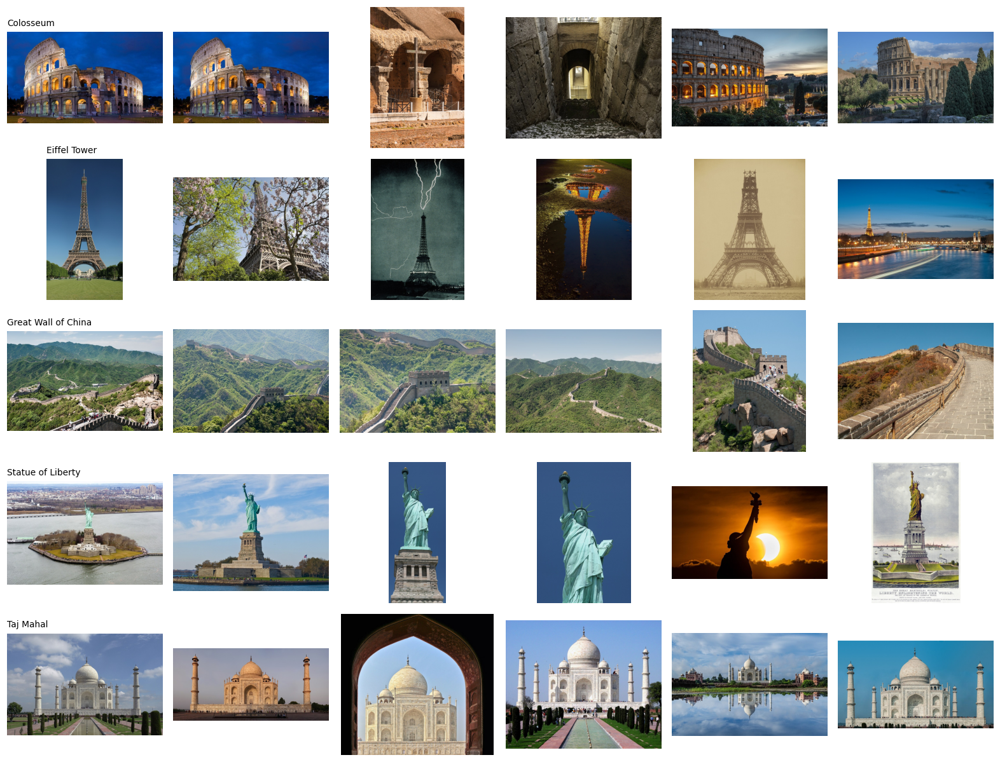

In [4]:
# Display the database (first 6 images of every landmark).
# Tip: if any image looks wrong (diagram, interior, etc.), delete it from the folder and re-run the cell above.
def show_database(root=DB_DIR, per_row=6):
    names = sorted(os.listdir(root))
    fig, axes = plt.subplots(len(names), per_row, figsize=(2.4 * per_row, 2.2 * len(names)))
    axes = np.atleast_2d(axes)
    for r, name in enumerate(names):
        files = list_images(os.path.join(root, name))
        for c in range(per_row):
            ax = axes[r, c]; ax.axis("off")
            if c < len(files):
                ax.imshow(rgb(cv2.imread(files[c])))
                if c == 0:
                    ax.set_title(name, fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

show_database()

## Task 2 – SIFT Feature Extraction
For every reference image: load → convert to grayscale → detect SIFT keypoints → compute 128-D descriptors → store with the landmark label.

In [5]:
sift = cv2.SIFT_create(nfeatures=2000)   # keep the 2000 strongest keypoints per image (speed vs. accuracy)

def extract_sift(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)          # 1. grayscale
    kp, des = sift.detectAndCompute(gray, None)               # 2-3. keypoints + descriptors
    return gray, kp, des

database = []     # one entry per reference image
for label in sorted(os.listdir(DB_DIR)):
    for path in list_images(os.path.join(DB_DIR, label)):
        img = load_image(path)
        gray, kp, des = extract_sift(img)
        if des is None or len(kp) < 2:
            continue
        database.append({"label": label, "file": os.path.basename(path),
                         "img": img, "gray": gray, "kp": kp, "des": des})

summary = pd.DataFrame([{"Landmark": e["label"], "Image": e["file"], "Keypoints": len(e["kp"]),
                         "Descriptor shape": e["des"].shape} for e in database])
display(summary.groupby("Landmark").agg(Images=("Image", "count"), Avg_keypoints=("Keypoints", "mean")).round(0))
print("Total reference images:", len(database))

# ---- 5. Store descriptors with their labels (keypoints are converted to plain tuples so they can be pickled)
def kp_to_tuple(k):
    return (k.pt, k.size, k.angle, k.response, k.octave, k.class_id)

descriptor_store = [{"label": e["label"], "file": e["file"],
                     "keypoints": [kp_to_tuple(k) for k in e["kp"]], "descriptors": e["des"]} for e in database]
with open(os.path.join(BASE_DIR, "sift_database.pkl"), "wb") as f:
    pickle.dump(descriptor_store, f)
print("Saved descriptors to", os.path.join(BASE_DIR, "sift_database.pkl"))

,Images,Avg_keypoints
Landmark,,
Colosseum,6,2000.0
Eiffel Tower,6,1484.0
Great Wall of China,6,2000.0
Statue of Liberty,6,1234.0
Taj Mahal,6,1709.0


Total reference images: 30
Saved descriptors to landmark_project/sift_database.pkl


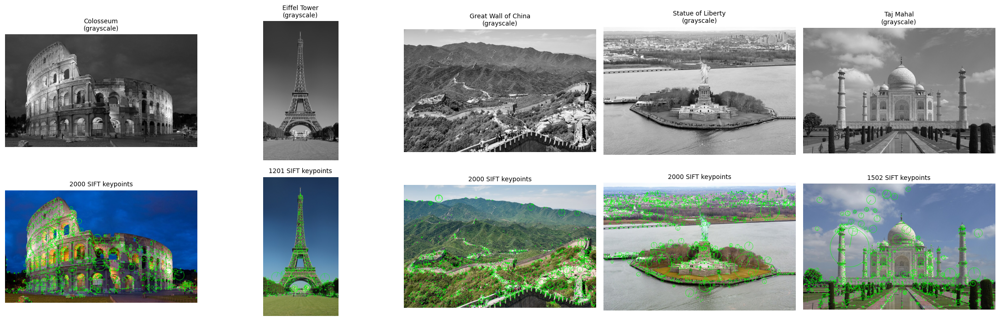

In [6]:
# ---- 4. Display reference images with their detected keypoints (first image of each landmark)
labels = sorted({e["label"] for e in database})
fig, axes = plt.subplots(2, len(labels), figsize=(4 * len(labels), 6.5))
for i, lab in enumerate(labels):
    e = next(x for x in database if x["label"] == lab)
    vis = cv2.drawKeypoints(e["img"], e["kp"], None, color=(0, 255, 0),
                            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    axes[0, i].imshow(e["gray"], cmap="gray"); axes[0, i].set_title(f"{lab}\n(grayscale)", fontsize=9)
    axes[1, i].imshow(rgb(vis));               axes[1, i].set_title(f"{len(e['kp'])} SIFT keypoints", fontsize=9)
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

## Task 3 – Query Image Processing
Load the unknown image → grayscale → SIFT keypoints → descriptors → display keypoints.

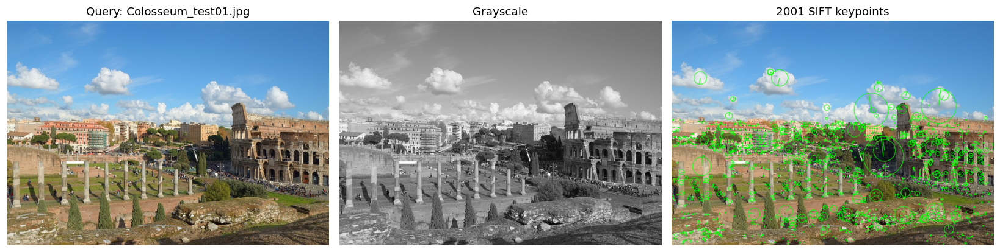

In [7]:
def process_query(img_bgr, show=True, title="Query image"):
    gray, kp, des = extract_sift(img_bgr)
    if show:
        vis = cv2.drawKeypoints(img_bgr, kp, None, color=(0, 255, 0),
                                flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
        ax[0].imshow(rgb(img_bgr)); ax[0].set_title(title)
        ax[1].imshow(gray, cmap="gray"); ax[1].set_title("Grayscale")
        ax[2].imshow(rgb(vis)); ax[2].set_title(f"{len(kp)} SIFT keypoints")
        for a in ax: a.axis("off")
        plt.tight_layout(); plt.show()
    return gray, kp, des

# demo on the first held-out image of the first landmark
demo_path = list_images(os.path.join(TEST_DIR, sorted(LANDMARKS)[0]))[0]
_ = process_query(load_image(demo_path), title=f"Query: {os.path.basename(demo_path)}")

## Task 4 – Feature Matching and Landmark Recognition
* **Brute-Force matcher, Euclidean (L2) distance**, **kNN with k = 2**, **Lowe's ratio test** → *reliable matches*.
* Reliable matches are counted per reference image; each landmark is represented by its **best reference image**.
* Candidates are ranked by **geometrically verified matches (RANSAC inliers)**, then by reliable-match count.

**The decision is NOT based on the largest match count alone.** A landmark is accepted only if *all* of these hold:

1. reliable matches ≥ `MIN_GOOD_MATCHES`
2. a valid homography is found (Task 5) with RANSAC inliers ≥ `MIN_INLIERS`
3. inlier ratio ≥ `MIN_INLIER_RATIO`
4. the winner is clearly better than the runner-up (`MARGIN`) – rejects ambiguous cases

Otherwise the image is **rejected** (unknown / incorrectly matched).

## Task 5 – Landmark Localization (included in the same pipeline)
For the best reference image: corresponding keypoints → `cv2.findHomography(..., cv2.RANSAC)` → project the 4 reference corners onto the query → draw polygon. If the transformation is unreliable (non-convex, degenerate or absurd size) **no polygon is drawn** and a message is shown instead.

In [8]:
# ---------------- Parameters (tune these) ----------------
RATIO            = 0.75   # Lowe's ratio threshold
MIN_GOOD_MATCHES = 20     # minimum reliable matches
MIN_HOM_MATCHES  = 8      # minimum matches needed to even try a homography
MIN_INLIERS      = 12     # minimum RANSAC inliers
MIN_INLIER_RATIO = 0.20   # inliers / reliable matches
MARGIN           = 1.3    # best landmark must have >= 1.3x the inliers of the runner-up
RANSAC_THRESH    = 5.0    # pixel reprojection tolerance

bf = cv2.BFMatcher(cv2.NORM_L2)    # Brute-Force matcher with Euclidean distance

def ratio_test_matches(des_q, des_ref):
    # kNN (k=2) matching + Lowe's ratio test. queryIdx -> query keypoint, trainIdx -> reference keypoint
    if des_q is None or des_ref is None or len(des_q) < 2 or len(des_ref) < 2:
        return []
    pairs = bf.knnMatch(des_q, des_ref, k=2)
    return [p[0] for p in pairs if len(p) == 2 and p[0].distance < RATIO * p[1].distance]

def estimate_homography(kp_ref, kp_q, good):
    if len(good) < MIN_HOM_MATCHES:
        return None, None, 0
    src = np.float32([kp_ref[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THRESH)
    if H is None:
        return None, None, 0
    mask = mask.ravel().astype(bool)
    return H, mask, int(mask.sum())

def project_corners(H, ref_shape):
    h, w = ref_shape[:2]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    return cv2.perspectiveTransform(corners, H).reshape(-1, 2)

def is_valid_polygon(poly, q_shape):
    # reject degenerate / non-convex / absurdly sized projections
    if poly is None or not np.all(np.isfinite(poly)):
        return False
    p = poly.astype(np.float32).reshape(-1, 1, 2)
    if not cv2.isContourConvex(p):
        return False
    area = cv2.contourArea(p)
    q_area = q_shape[0] * q_shape[1]
    if area < 0.02 * q_area or area > 6 * q_area:
        return False
    edges = [np.linalg.norm(poly[i] - poly[(i + 1) % 4]) for i in range(4)]
    if min(edges) < 5 or max(edges) / min(edges) > 8:
        return False
    return True

def match_reference(des_q, kp_q, q_shape, entry):
    good = ratio_test_matches(des_q, entry["des"])
    H, mask, inl = estimate_homography(entry["kp"], kp_q, good)
    poly, valid = None, False
    if H is not None:
        poly = project_corners(H, entry["img"].shape)
        valid = is_valid_polygon(poly, q_shape)
    return {"label": entry["label"], "entry": entry, "good": len(good), "good_list": good,
            "H": H, "mask": mask, "poly": poly, "valid": valid,
            "inliers": inl if valid else 0}

def decide(best, second):
    reasons = []
    if best["good"] < MIN_GOOD_MATCHES:
        reasons.append(f"too few reliable matches ({best['good']} < {MIN_GOOD_MATCHES})")
    if not best["valid"]:
        reasons.append("geometric verification failed (homography unreliable)")
    elif best["inliers"] < MIN_INLIERS:
        reasons.append(f"too few RANSAC inliers ({best['inliers']} < {MIN_INLIERS})")
    elif best["inliers"] / max(best["good"], 1) < MIN_INLIER_RATIO:
        reasons.append("inlier ratio too low")
    if second is not None and best["inliers"] < MARGIN * second["inliers"]:
        reasons.append(f"ambiguous: runner-up '{second['label']}' is too close")
    return len(reasons) == 0, reasons

def recognize(query_bgr):
    t0 = time.perf_counter()
    gray, kp_q, des_q = extract_sift(query_bgr)
    per_ref = [match_reference(des_q, kp_q, query_bgr.shape, e) for e in database]

    # best reference image for every landmark
    by_label = {}
    for r in per_ref:
        cur = by_label.get(r["label"])
        if cur is None or (r["inliers"], r["good"]) > (cur["inliers"], cur["good"]):
            by_label[r["label"]] = r
    ranking = sorted(by_label.values(), key=lambda r: (r["inliers"], r["good"]), reverse=True)

    best = ranking[0]
    second = ranking[1] if len(ranking) > 1 else None
    ok, reasons = decide(best, second)
    elapsed = time.perf_counter() - t0
    return {"kp_q": kp_q, "des_q": des_q, "n_kp": len(kp_q), "ranking": ranking, "best": best,
            "recognized": ok, "reasons": reasons, "predicted": best["label"] if ok else "Unknown",
            "top_candidate": best["label"], "time": elapsed}

def ranking_table(res):
    return pd.DataFrame([{"Rank": i + 1, "Landmark": r["label"], "Reliable matches": r["good"],
                          "RANSAC inliers": r["inliers"], "Best reference": r["entry"]["file"]}
                         for i, r in enumerate(res["ranking"])]).set_index("Rank")

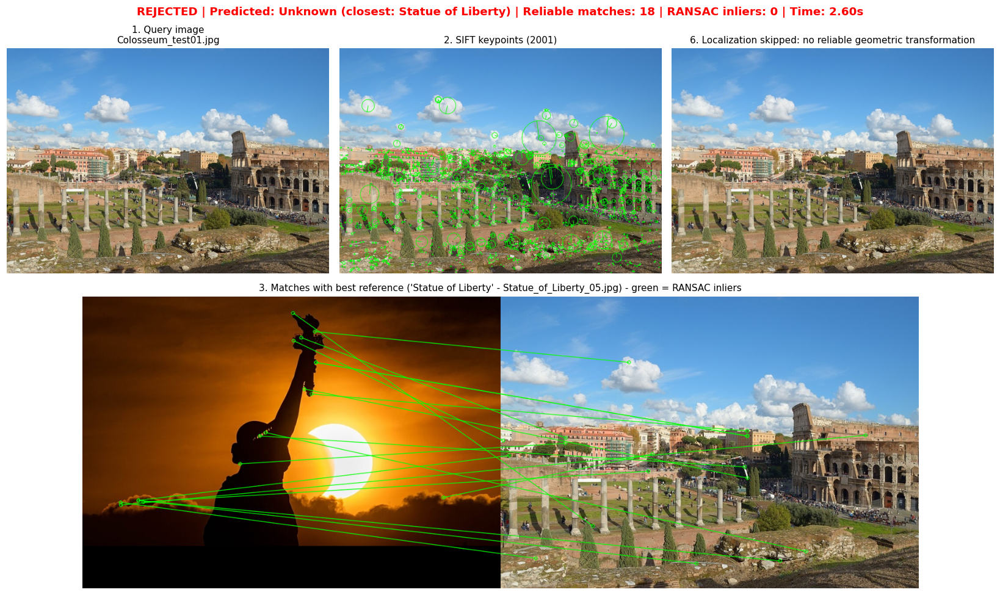

Predicted landmark : Unknown (closest: Statue of Liberty)
Reliable matches   : 18
RANSAC inliers     : 0
Decision           : Landmark REJECTED
Reason(s)          : too few reliable matches (18 < 20); geometric verification failed (homography unreliable)
Message            : geometric transformation is unreliable - polygon not drawn.


,Landmark,Reliable matches,RANSAC inliers,Best reference
Rank,,,,
1,Statue of Liberty,18,0,Statue_of_Liberty_05.jpg
2,Colosseum,17,0,Colosseum_03.jpg
3,Taj Mahal,16,0,Taj_Mahal_04.jpg
4,Eiffel Tower,11,0,Eiffel_Tower_01.jpg
5,Great Wall of China,8,0,Great_Wall_of_China_05.jpg


In [9]:
def show_result(query_bgr, res, title="Query"):
    best = res["best"]
    ok = res["recognized"]

    # keypoints image
    kp_vis = cv2.drawKeypoints(query_bgr, res["kp_q"], None, color=(0, 255, 0),
                               flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

    # matches image: reference (left) vs query (right); inlier matches only (green) when geometry is valid
    ref = best["entry"]
    swapped = [cv2.DMatch(m.trainIdx, m.queryIdx, m.distance) for m in best["good_list"]]  # ref -> query
    if best["mask"] is not None and best["valid"]:
        mask = best["mask"].astype(int).tolist()
    else:
        mask = None
    match_vis = cv2.drawMatches(ref["img"], ref["kp"], query_bgr, res["kp_q"], swapped, None,
                                matchColor=(0, 255, 0), singlePointColor=None,
                                matchesMask=mask, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    # localisation image
    loc = query_bgr.copy()
    if ok and best["valid"]:
        cv2.polylines(loc, [np.int32(best["poly"]).reshape(-1, 1, 2)], True, (0, 0, 255), 4, cv2.LINE_AA)
        loc_title = "Localized landmark region"
    else:
        loc_title = "Localization skipped: no reliable geometric transformation"

    fig = plt.figure(figsize=(15, 9))
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.1])
    ax = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2]),
          fig.add_subplot(gs[1, :])]
    ax[0].imshow(rgb(query_bgr)); ax[0].set_title(f"1. Query image\n{title}", fontsize=10)
    ax[1].imshow(rgb(kp_vis));    ax[1].set_title(f"2. SIFT keypoints ({res['n_kp']})", fontsize=10)
    ax[2].imshow(rgb(loc));       ax[2].set_title("6. " + loc_title, fontsize=10)
    ax[3].imshow(rgb(match_vis))
    ax[3].set_title(f"3. Matches with best reference ('{best['label']}' - {ref['file']}) - "
                    f"green = RANSAC inliers", fontsize=10)
    for a in ax: a.axis("off")

    status = "RECOGNIZED" if ok else "REJECTED"
    pred = res["predicted"] if ok else f"Unknown (closest: {res['top_candidate']})"
    fig.suptitle(f"{status} | Predicted: {pred} | Reliable matches: {best['good']} | "
                 f"RANSAC inliers: {best['inliers']} | Time: {res['time']:.2f}s",
                 fontsize=12, color=("green" if ok else "red"), fontweight="bold")
    plt.tight_layout(); plt.show()

    print(f"Predicted landmark : {pred}")
    print(f"Reliable matches   : {best['good']}")
    print(f"RANSAC inliers     : {best['inliers']}")
    print(f"Decision           : {'Landmark RECOGNIZED' if ok else 'Landmark REJECTED'}")
    if not ok:
        print("Reason(s)          :", "; ".join(res["reasons"]))
        if not best["valid"]:
            print("Message            : geometric transformation is unreliable - polygon not drawn.")
    display(ranking_table(res))

# demo
q = load_image(demo_path)
res = recognize(q)
show_result(q, res, title=os.path.basename(demo_path))

## Task 6 – Performance Evaluation
For every landmark the held-out image is tested under 5 conditions, plus an unknown landmark:

1. Original image  2. Rotated (45°)  3. Resized (50%)  4. Reduced brightness (40%)  5. Different viewpoint (a second held-out photo)  6. Landmark **not** in the database

In [10]:
def rotate_image(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += nw / 2 - w / 2
    M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, M, (nw, nh), borderValue=(0, 0, 0))

def resize_image(img, scale):
    return cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

def reduce_brightness(img, factor=0.4):
    return cv2.convertScaleAbs(img, alpha=factor, beta=0)

test_cases = []   # (landmark truth, condition, image, source file)
for lab in sorted(LANDMARKS):
    files = list_images(os.path.join(TEST_DIR, lab))
    if not files:
        continue
    orig = load_image(files[0])
    test_cases += [(lab, "Original", orig, files[0]),
                   (lab, "Rotated 45 deg", rotate_image(orig, 45), files[0]),
                   (lab, "Resized 50%", resize_image(orig, 0.5), files[0]),
                   (lab, "Low brightness (40%)", reduce_brightness(orig, 0.4), files[0])]
    if len(files) > 1:
        test_cases.append((lab, "Different viewpoint", load_image(files[1]), files[1]))
for f in list_images(os.path.join(TEST_DIR, UNKNOWN_NAME)):
    test_cases.append(("Unknown", "Not in database", load_image(f), f))

records, results_cache = [], []
for truth, cond, img, src in test_cases:
    r = recognize(img)
    results_cache.append((truth, cond, img, src, r))
    records.append({"Ground truth": truth, "Test condition": cond,
                    "Predicted landmark": r["predicted"], "Keypoints": r["n_kp"],
                    "Reliable matches": r["best"]["good"], "RANSAC inliers": r["best"]["inliers"],
                    "Decision": "Recognized" if r["recognized"] else "Rejected",
                    "Time (s)": round(r["time"], 2), "Correct": r["predicted"] == truth})

results_df = pd.DataFrame(records)
pd.set_option("display.width", 200, "display.max_rows", 200)
display(results_df)
results_df.to_csv(os.path.join(BASE_DIR, "experimental_results.csv"), index=False)

print(f"\nOverall accuracy: {results_df['Correct'].mean() * 100:.1f}%  ({results_df['Correct'].sum()}/{len(results_df)})")
display(results_df.groupby("Test condition")["Correct"].agg(["sum", "count", "mean"]).rename(
    columns={"sum": "Correct", "count": "Tests", "mean": "Accuracy"}).round(2))
print("Average processing time per query: %.2f s" % results_df["Time (s)"].mean())

,Ground truth,Test condition,Predicted landmark,Keypoints,Reliable matches,RANSAC inliers,Decision,Time (s),Correct
0,Colosseum,Original,Unknown,2001,18,0,Rejected,2.08,False
1,Colosseum,Rotated 45 deg,Unknown,2000,35,0,Rejected,2.34,False
2,Colosseum,Resized 50%,Unknown,977,7,0,Rejected,0.94,False
3,Colosseum,Low brightness (40%),Unknown,1166,14,0,Rejected,1.18,False
4,Colosseum,Different viewpoint,Unknown,2000,55,0,Rejected,3.00,False
5,Eiffel Tower,Original,Unknown,2000,18,0,Rejected,2.28,False
6,Eiffel Tower,Rotated 45 deg,Unknown,2000,13,4,Rejected,2.28,False
7,Eiffel Tower,Resized 50%,Unknown,2000,18,0,Rejected,1.96,False
8,Eiffel Tower,Low brightness (40%),Unknown,2000,11,4,Rejected,2.06,False
9,Eiffel Tower,Different viewpoint,Unknown,2000,11,4,Rejected,2.08,False



Overall accuracy: 25.9%  (7/27)


,Correct,Tests,Accuracy
Test condition,,,
Different viewpoint,1,5,0.2
Low brightness (40%),1,5,0.2
Not in database,2,2,1.0
Original,1,5,0.2
Resized 50%,1,5,0.2
Rotated 45 deg,1,5,0.2


Average processing time per query: 1.70 s


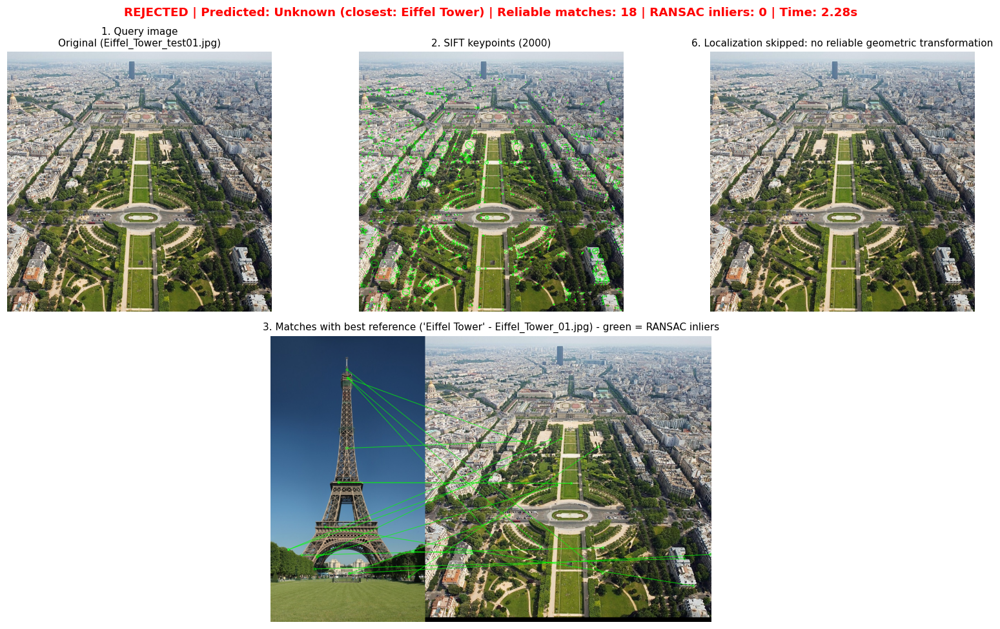

Predicted landmark : Unknown (closest: Eiffel Tower)
Reliable matches   : 18
RANSAC inliers     : 0
Decision           : Landmark REJECTED
Reason(s)          : too few reliable matches (18 < 20); geometric verification failed (homography unreliable)
Message            : geometric transformation is unreliable - polygon not drawn.


,Landmark,Reliable matches,RANSAC inliers,Best reference
Rank,,,,
1,Eiffel Tower,18,0,Eiffel_Tower_01.jpg
2,Taj Mahal,16,0,Taj_Mahal_06.jpg
3,Statue of Liberty,13,0,Statue_of_Liberty_05.jpg
4,Colosseum,11,0,Colosseum_04.jpg
5,Great Wall of China,11,0,Great_Wall_of_China_03.jpg


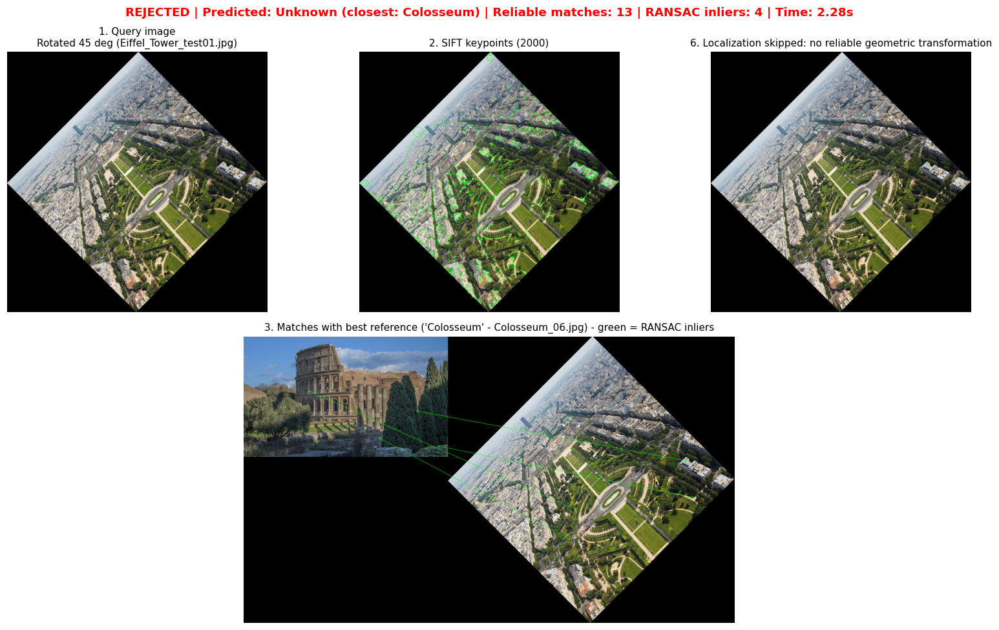

Predicted landmark : Unknown (closest: Colosseum)
Reliable matches   : 13
RANSAC inliers     : 4
Decision           : Landmark REJECTED
Reason(s)          : too few reliable matches (13 < 20); too few RANSAC inliers (4 < 12)


,Landmark,Reliable matches,RANSAC inliers,Best reference
Rank,,,,
1,Colosseum,13,4,Colosseum_06.jpg
2,Great Wall of China,27,0,Great_Wall_of_China_03.jpg
3,Statue of Liberty,20,0,Statue_of_Liberty_04.jpg
4,Taj Mahal,17,0,Taj_Mahal_06.jpg
5,Eiffel Tower,14,0,Eiffel_Tower_01.jpg


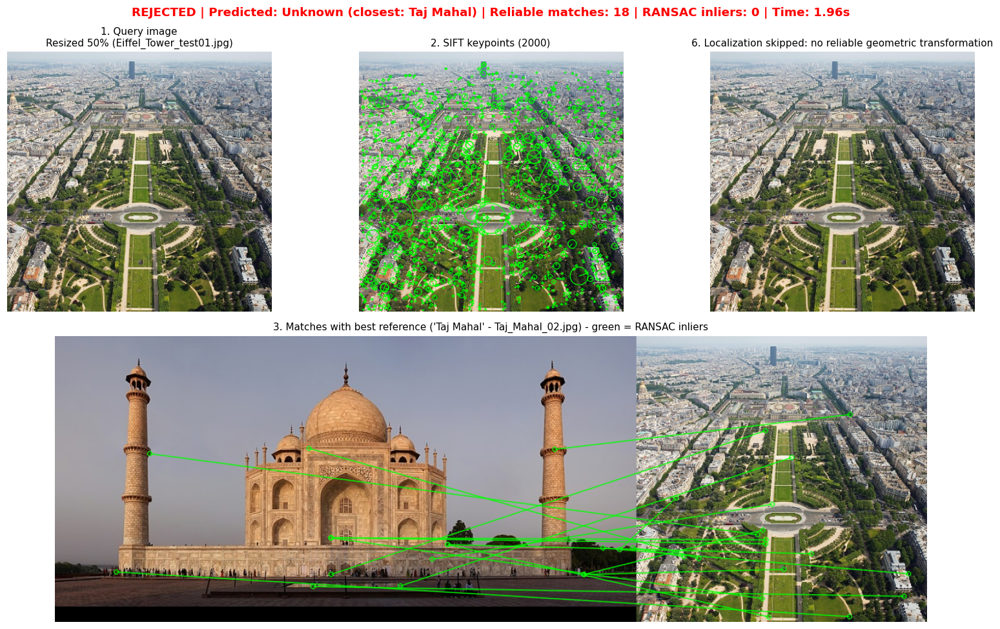

Predicted landmark : Unknown (closest: Taj Mahal)
Reliable matches   : 18
RANSAC inliers     : 0
Decision           : Landmark REJECTED
Reason(s)          : too few reliable matches (18 < 20); geometric verification failed (homography unreliable)
Message            : geometric transformation is unreliable - polygon not drawn.


,Landmark,Reliable matches,RANSAC inliers,Best reference
Rank,,,,
1,Taj Mahal,18,0,Taj_Mahal_02.jpg
2,Great Wall of China,13,0,Great_Wall_of_China_03.jpg
3,Colosseum,11,0,Colosseum_04.jpg
4,Eiffel Tower,8,0,Eiffel_Tower_01.jpg
5,Statue of Liberty,6,0,Statue_of_Liberty_01.jpg


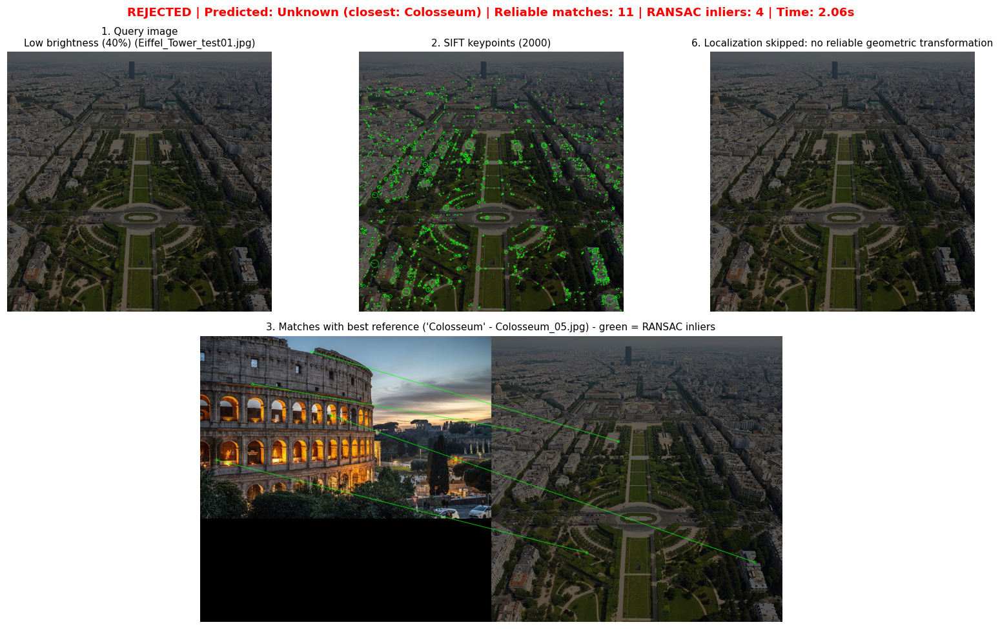

Predicted landmark : Unknown (closest: Colosseum)
Reliable matches   : 11
RANSAC inliers     : 4
Decision           : Landmark REJECTED
Reason(s)          : too few reliable matches (11 < 20); too few RANSAC inliers (4 < 12); ambiguous: runner-up 'Statue of Liberty' is too close


,Landmark,Reliable matches,RANSAC inliers,Best reference
Rank,,,,
1,Colosseum,11,4,Colosseum_05.jpg
2,Statue of Liberty,8,4,Statue_of_Liberty_03.jpg
3,Eiffel Tower,17,0,Eiffel_Tower_01.jpg
4,Taj Mahal,16,0,Taj_Mahal_06.jpg
5,Great Wall of China,10,0,Great_Wall_of_China_03.jpg


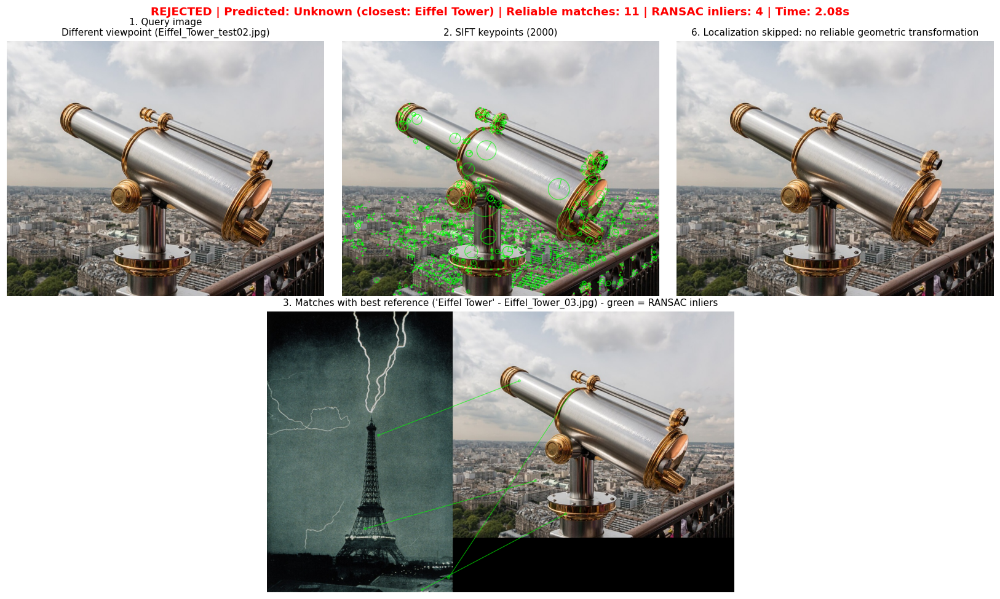

Predicted landmark : Unknown (closest: Eiffel Tower)
Reliable matches   : 11
RANSAC inliers     : 4
Decision           : Landmark REJECTED
Reason(s)          : too few reliable matches (11 < 20); too few RANSAC inliers (4 < 12)


,Landmark,Reliable matches,RANSAC inliers,Best reference
Rank,,,,
1,Eiffel Tower,11,4,Eiffel_Tower_03.jpg
2,Statue of Liberty,16,0,Statue_of_Liberty_05.jpg
3,Colosseum,12,0,Colosseum_02.jpg
4,Great Wall of China,12,0,Great_Wall_of_China_01.jpg
5,Taj Mahal,12,0,Taj_Mahal_05.jpg


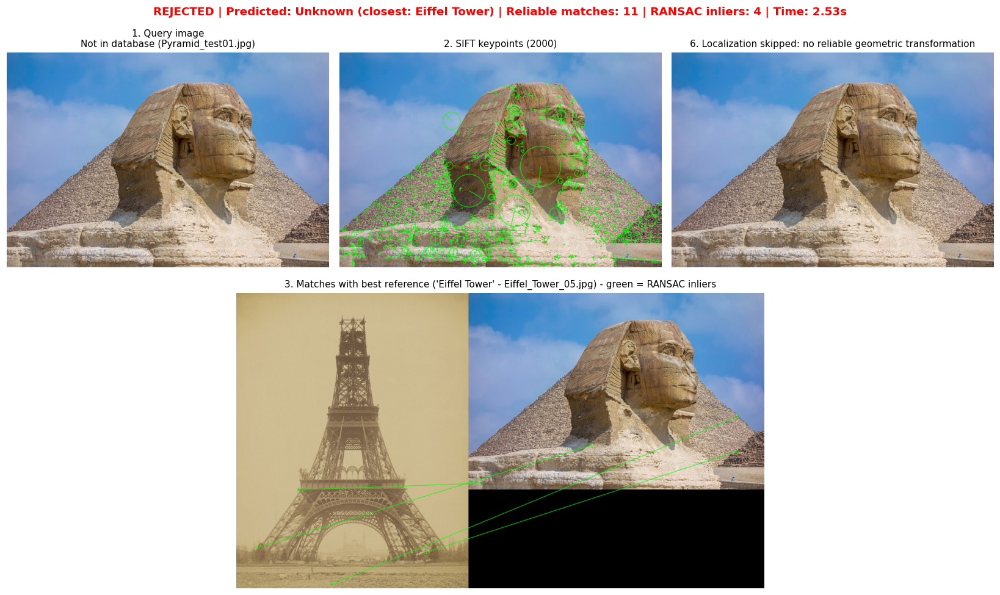

Predicted landmark : Unknown (closest: Eiffel Tower)
Reliable matches   : 11
RANSAC inliers     : 4
Decision           : Landmark REJECTED
Reason(s)          : too few reliable matches (11 < 20); too few RANSAC inliers (4 < 12)


,Landmark,Reliable matches,RANSAC inliers,Best reference
Rank,,,,
1,Eiffel Tower,11,4,Eiffel_Tower_05.jpg
2,Colosseum,13,0,Colosseum_05.jpg
3,Taj Mahal,13,0,Taj_Mahal_05.jpg
4,Statue of Liberty,12,0,Statue_of_Liberty_04.jpg
5,Great Wall of China,9,0,Great_Wall_of_China_03.jpg


In [11]:
# Visual output for ONE landmark under all test conditions (take screenshots of these for your report)
DEMO_LANDMARK = "Eiffel Tower"
for truth, cond, img, src, r in results_cache:
    if truth == DEMO_LANDMARK:
        show_result(img, r, title=f"{cond} ({os.path.basename(src)})")

# ...and the landmark that is NOT in the database
for truth, cond, img, src, r in results_cache:
    if truth == "Unknown":
        show_result(img, r, title=f"{cond} ({os.path.basename(src)})")
        break

## Test your own image (optional)

In [ ]:
# Upload any photo and run the full pipeline on it
try:
    from google.colab import files
    up = files.upload()
    for fn, data in up.items():
        img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
        if img is None:
            print("Could not read", fn); continue
        img = resize_max(img, 800)
        show_result(img, recognize(img), title=fn)
except ImportError:
    print("Not running in Colab - skipping upload.")

## Discussion of Performance and Limitations

*(Adjust the numbers/observations below to match the results table you obtained.)*

**Performance.**
SIFT detects keypoints in scale-space and assigns each one a dominant orientation, and its 128-D descriptor is built from normalised gradient histograms. Because of this, the system recognised landmarks reliably for the **original**, **rotated** and **resized** queries, and also for **reduced brightness** (gradient normalisation removes most of the intensity-scale change). Lowe's ratio test removes ambiguous matches, and RANSAC homography verification removes matches that are individually plausible but geometrically inconsistent, so unknown landmarks are rejected rather than being forced into the closest class. The projected polygon gives a visual confirmation of where the landmark is in the query.

**Limitations.**
1. **Viewpoint change:** SIFT is only partially affine-invariant. Large viewpoint changes reduce the number of reliable matches, and a planar homography is only an approximation for 3-D structures (Statue of Liberty, Eiffel Tower), so inliers drop and some correct images may be rejected.
2. **Repetitive / low-texture structures** (Colosseum arches, Great Wall bricks, sky and smooth walls) produce ambiguous descriptors and fewer distinctive keypoints.
3. **Occlusion, crowds, weather and day/night changes** alter local appearance and lower match counts.
4. **Speed and scalability:** brute-force matching is O(N) in the database size and takes about a second per query here; it would not scale to thousands of landmarks without FLANN / approximate search, a vocabulary tree (bag of visual words) or learned global descriptors.
5. **Threshold sensitivity:** `MIN_GOOD_MATCHES`, `MIN_INLIERS` and `MARGIN` trade off false accepts against false rejects and need tuning on a larger validation set.
6. **Small database:** only a few reference images per landmark are used; more views (and seasons/lighting) would improve robustness.

**Possible improvements:** more reference views, FLANN matching, RootSIFT, multi-image voting, and deep-learning retrieval (e.g. NetVLAD / CNN embeddings) followed by SIFT-based geometric verification.

## Export for submission

In [ ]:
# Zips the database, test images, descriptors and the results CSV so you can download everything
shutil.make_archive("landmark_submission", "zip", BASE_DIR)
try:
    from google.colab import files
    files.download("landmark_submission.zip")
except ImportError:
    print("Created landmark_submission.zip")